In [1]:
import tensorflow as tf

In [9]:
import keras

In [10]:
from keras import layers

In [23]:
import matplotlib.pyplot as plt

In [24]:
import numpy as np 

In [15]:
(x_train,y_train),(x_test,y_test) = keras.datasets.mnist.load_data()

In [16]:
print("Training images:", x_train.shape)

Training images: (60000, 28, 28)


In [17]:
print("training labels:",y_train.shape)

training labels: (60000,)


In [18]:
print("testing images:",x_test.shape)

testing images: (10000, 28, 28)


In [19]:
print("testing labels:",y_test.shape)

testing labels: (10000,)


In [20]:
x_train = x_train.astype("float32")/255.0

In [21]:
x_test = x_test.astype("float32")/255.0

In [25]:
plt.figure(figsize=(10,5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

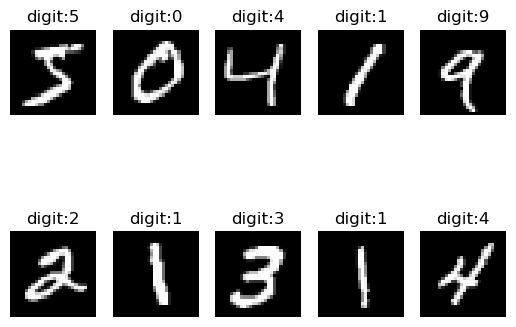

In [26]:
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i],cmap="gray")
    plt.title("digit:"+str(y_train[i]))
    plt.axis("off")
plt.show()  

In [27]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])


In [28]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8241 - loss: 0.5840 - val_accuracy: 0.9398 - val_loss: 0.2084
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9214 - loss: 0.2688 - val_accuracy: 0.9593 - val_loss: 0.1446
Epoch 3/10
419/422 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9395 - loss: 0.2026

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

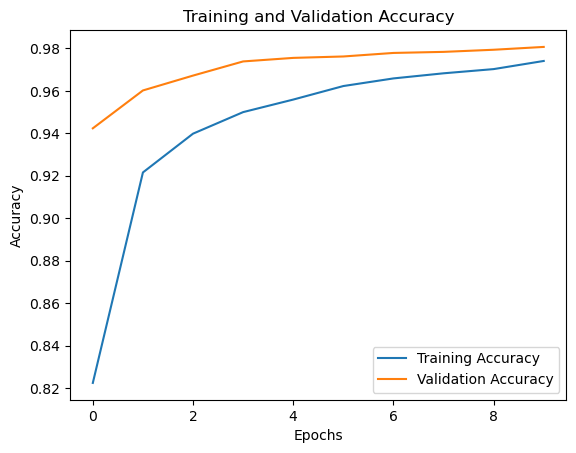

In [31]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [32]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9763 - loss: 0.0769  
Test Loss: 0.07689855247735977
Test Accuracy: 97.63000011444092 %


In [33]:
predictions = model.predict(x_test[:10])

for i in range(10):
    predicted_digit = np.argmax(predictions[i])
    actual_digit = y_test[i]

    print("Actual Digit:", actual_digit,
          "Predicted Digit:", predicted_digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
Actual Digit: 7 Predicted Digit: 7
Actual Digit: 2 Predicted Digit: 2
Actual Digit: 1 Predicted Digit: 1
Actual Digit: 0 Predicted Digit: 0
Actual Digit: 4 Predicted Digit: 4
Actual Digit: 1 Predicted Digit: 1
Actual Digit: 4 Predicted Digit: 4
Actual Digit: 9 Predicted Digit: 9
Actual Digit: 5 Predicted Digit: 6
Actual Digit: 9 Predicted Digit: 9


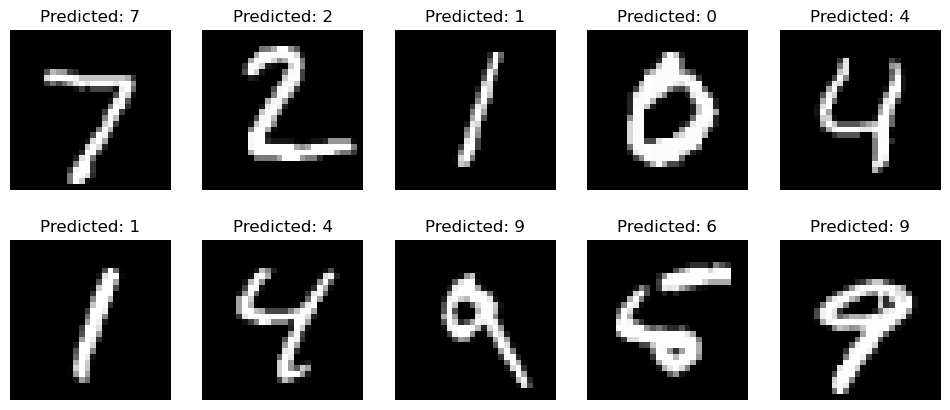

In [34]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Predicted: " + str(np.argmax(predictions[i])))
    plt.axis("off")

plt.show()

In [6]:
!pip install scikit-learn

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict all testing images
y_pred = model.predict(x_test)

# Convert predicted probabilities into digit labels
y_pred = np.argmax(y_pred, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - MNIST")
plt.show()

NameError: name 'model' is not defined